# Experimental Structural Modal Reconstruction

Recover seven damped structural modes, complex spatial residues and residual terms from six measured accelerance responses with overlapping resonances and finite frequency coverage.

This maintainer notebook actively reconstructs the complete bound observations with local numerical modules. It distinguishes the independently reproduced original method from fresh cleaned results. There is no cache-preview path. The paper describes the selected model; the exact bound dataset and modern port have separate provenance.

## Observation and inverse problem

For angular frequency omega=2πf, the complex accelerance at roving excitation index l is modeled as
```math
H_l(\omega)=-\omega^2\sum_{k=1}^{7}\left[\frac{A_{lk}}{\mathrm{i}\omega-p_k}+\frac{\overline{A_{lk}}}{\mathrm{i}\omega-\overline{p_k}}\right]+L_l-\omega^2U_l.
```
Here f is frequency in Hz, p is a stable modal pole in s^-1, A is a complex residue in m/(N·s), the overbar is complex conjugation, L is the lower residual in m/(N·s²), and U is the upper residual in m/N. Natural frequency is abs(p)/(2π) Hz, and damping ratio is -Re(p)/abs(p). L and U represent contributions outside the fitted frequency band. Real physical impulse responses give conjugate pole pairs.

The bound observation consists of all 9999 frequency bins for each of six roving excitations at the fixed response index selected in the author showcase. Identify seven modes within the 10–5000 Hz analysis band and their complete six-location complex residues. Pole-residue factorization is sensitive to noise, polynomial order and out-of-band contributions; no measured spatial distances are supplied.

## Implemented mathematics and numerical conventions

Use all native bins for the bound fixed-response experiment, but the selected method first truncates before the closest 5000 Hz sample. Set sampling interval dt=1/(2*f_last_retained) from the retained native grid before prepending missing bins from zero in steps df=f[1]-f[0]. The padded FRF columns are zeros. This preserves source conventions rather than pretending the input starts at DC. Analysis lower bin is closest 10 Hz. Maximum denominator degree is 120 (60 even polynomial orders).

For order limit n=120 and nf=2*(number_of_padded_bins-1), define adjusted inverse transforms F(x,q)=nf*irfft(x)[q]-nf*irfft(x[:lower])[q], keeping the two multiplications separate. Compute s=-F(H,q), q=-n..n; t=F(Re(H)²+Im(H)²,q), q=0..n; r=-nf*irfft(ones(lower))[0..n], then r[0]+=nf. Build Toeplitz S_l from the signed s sequence, T from sum_l(t_l), and R from r. At every even degree j, D_j=T_j-sum_l S_l,jᵀ R_j^-1 S_l,j. Solve -D[0:j,0:j]a=D[0:j,j], append last coefficient 1, reverse polynomial coefficient order for np.roots, and map roots z to p=-log(z)/dt. No nonlinear optimizer or arbitrary regularizer is used in this pole step.

Stabilization uses the source's signed frequency |p| sign(Im p)/(2π), damping -Re p/(|p| sign(Im p)), removes conjugate-frequency duplicates within 1e-3 Hz, and requires relative frequency change <0.001 and relative damping change <0.05 with positive damping. Preserve source order indexing, including its n=1 seed-order convention. Approximate observed resonance centers are [176,476,932,1534,2258,3161,4180] Hz. Recenter each using least_squares on stable frequencies in successively narrowed windows [25,16,12,10,8,7,6,5,5,4,4,4,3?] as actually generated by [50//i for i in range(2,100) if 50//i>3]+[2]; the executable comprehension is authoritative (no 3 Hz entry). Select the closest actual polynomial pole to the stabilized representative. These approximate centers are model initialization, not submitted answers or acquisition calibration.

For LSFD, evaluate the stated complex conjugate-residue formula separately for unit real and imaginary residue coefficients. Append real/imaginary columns for L and -omega² U. Stack real and imaginary observation equations and solve np.linalg.lstsq(rcond=None) over closest 10 Hz through the exclusive final retained bin. The returned natural frequency/damping are the stabilized representatives; residues use the selected actual polynomial poles, matching the source's subtle distinction. Coefficients and forward arrays retain their physical complex scale, without mode normalization. Notebook normalized real residues are explicitly display-only.

Root calculations on ill-conditioned high-order normal equations are sensitive to arithmetic grouping. Preserve Re(H)²+Im(H)² instead of abs(H)² and accumulate the negative S terms before adding T. Independent pole-residue analytic tests validate the signs and physical units. No structural geometry, displacement field or mass normalization is invented from the FRFs.

In [1]:
%matplotlib inline
from pathlib import Path
import os,sys,time,json,subprocess,hashlib
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
ROOT=next(p for p in [Path.cwd(),Path.cwd().parent] if (p/'src').is_dir())
os.chdir(ROOT)
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
from src.preprocessing import load_data
from src.main import run
from src.visualization import make_figures,relative_error
data=load_data()
display(Markdown('| Observation | Internal shape | Dtype |\n| --- | --- | --- |\n'+'\n'.join(f'| {k} | {v.shape} | {v.dtype} |' for k,v in data.items())))

| Observation | Internal shape | Dtype |
| --- | --- | --- |
| frequency | (9999,) | float64 |
| accelerance | (6, 9999) | complex128 |

## Fresh full reconstruction

The standard local path below computes every required output quantity from the bound public measurements and writes the declared submission. Runtime includes the complete reconstruction. Evaluation is a separate subprocess using the standalone Judge.

In [2]:
start=time.perf_counter()
fresh=run()
solver_runtime_s=time.perf_counter()-start
judge_process=subprocess.run([sys.executable,'evaluation/judge.py','--prediction','output/reconstruction.npz','--report','output/judge_report.json'],capture_output=True,text=True,encoding='utf8',env=dict(os.environ,PYTHONIOENCODING='utf-8'))
assert judge_process.returncode==0,judge_process.stderr
judge_report=json.loads(Path('output/judge_report.json').read_text(encoding='utf8'))
assert judge_report['status']=='pass'
with np.load('evaluation/baseline_reference.npz',allow_pickle=False) as f:reference={k:f[k].copy() for k in f.files}
agreement={key:relative_error(fresh[key],reference[key]) for key in fresh}
print(json.dumps({'identity':'fresh cleaned full reconstruction','solver_runtime_s':solver_runtime_s,'upstream_relative_errors':agreement,'standalone_judge':judge_report},indent=2,allow_nan=False))

{
  "identity": "fresh cleaned full reconstruction",
  "solver_runtime_s": 0.14118659985251725,
  "upstream_relative_errors": {
    "natural_frequency": 0.0,
    "damping_ratio": 0.0,
    "reconstruction": 4.087714252067929e-12,
    "fitted_accelerance": 5.755036312835917e-13,
    "lower_residual": 3.774289640682057e-12,
    "upper_residual": 4.029933856110276e-12
  },
  "standalone_judge": {
    "status": "pass",
    "passed": true,
    "metrics": {
      "natural_frequency_0_relative_error": 0.0,
      "natural_frequency_1_relative_error": 0.0,
      "natural_frequency_2_relative_error": 0.0,
      "natural_frequency_3_relative_error": 0.0,
      "natural_frequency_4_relative_error": 0.0,
      "natural_frequency_5_relative_error": 0.0,
      "natural_frequency_6_relative_error": 0.0,
      "damping_ratio_0_relative_error": 0.0,
      "damping_ratio_1_relative_error": 0.0,
      "damping_ratio_2_relative_error": 0.0,
      "damping_ratio_3_relative_error": 0.0,
      "damping_ratio_4

## Scientific comparisons and recomputed experiments

The reconstruction figure includes measured signal consistency and independently reproduced upstream comparison. The robustness figure recomputes its model/regularization and acquisition/calibration changes. Original arrays are comparison inputs only; every curve labeled fresh is computed here. Exact numerical trace arrays are returned for the separately archived figure exports.

In [3]:
experiment_start=time.perf_counter()
figures,plot_trace,experiment_metrics=make_figures(data,fresh,reference)
plt.close('all')
experiment_runtime_s=time.perf_counter()-experiment_start
measurement={'identity':'fresh cleaned notebook reconstruction and actively recomputed comparisons','raw_data_sha256':hashlib.sha256(Path('data/raw_data.npz').read_bytes()).hexdigest(),'solver_runtime_s':solver_runtime_s,'experiments_runtime_s':experiment_runtime_s,'upstream_relative_errors':agreement,'scientific_measurements':experiment_metrics,'judge':judge_report,'historical_paper_numbers_used':False}
Path('notebooks/reference_outputs/fresh_measurements.json').write_text(json.dumps(measurement,indent=2,allow_nan=False)+'\n',encoding='utf8')
print(json.dumps(experiment_metrics,indent=2,allow_nan=False))

{
  "upstream_relative_error": 4.087714252067929e-12,
  "observation_relative_error": 0.10063998896074228,
  "order_relative_response_error": [
    [
      30,
      0.057664209678194016
    ],
    [
      45,
      0.07572940092911881
    ],
    [
      60,
      0.10063998896074228
    ]
  ],
  "natural_frequency_Hz": [
    177.04999133050524,
    477.3658804994738,
    933.0989430562875,
    1535.48268783097,
    2286.8635109688444,
    3162.522893402961,
    4181.873921214116
  ],
  "damping_ratio": [
    0.00795425414360068,
    0.0017156741229151053,
    0.0015388540505181423,
    0.0019519496093310415,
    0.0028018169835659712,
    0.002300946023924018,
    0.0014783437135855578
  ]
}


### Reconstruction

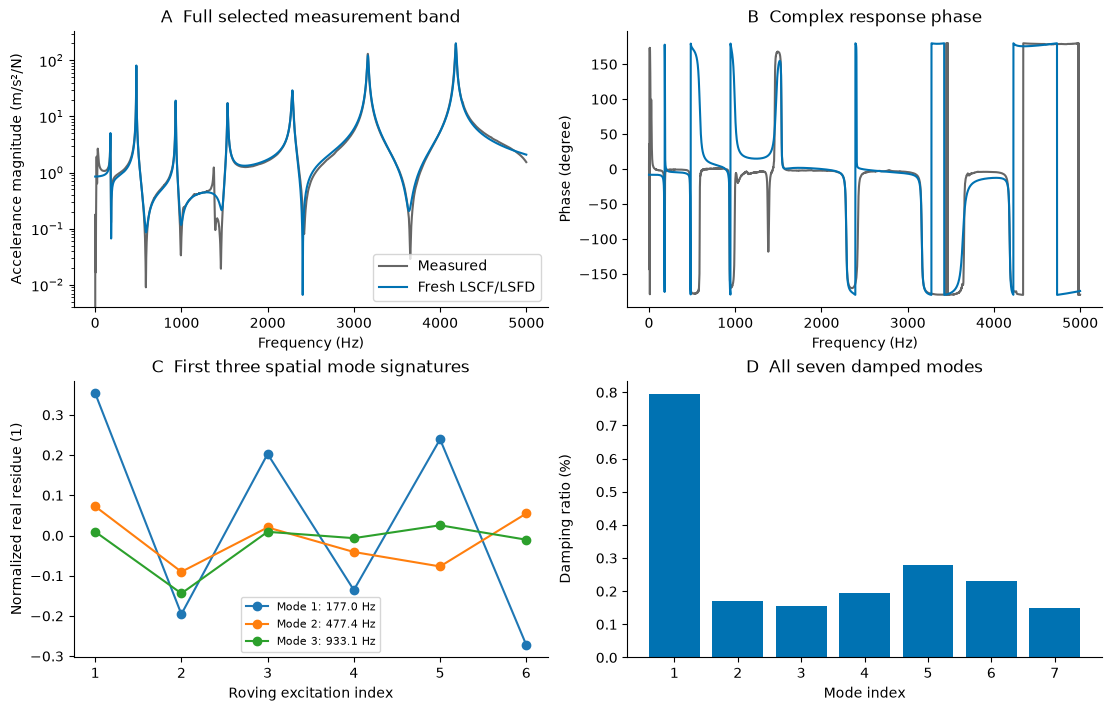

### Robustness

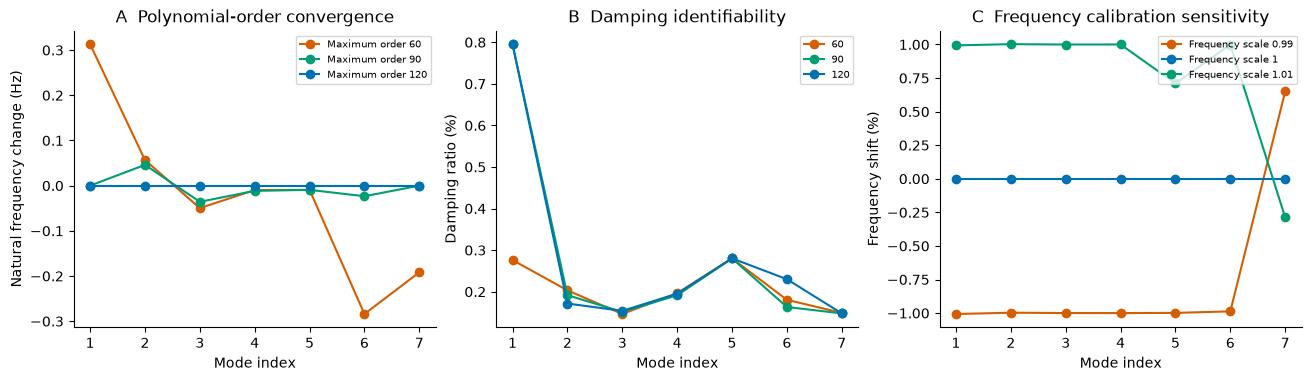

### Inverse Diagnostics

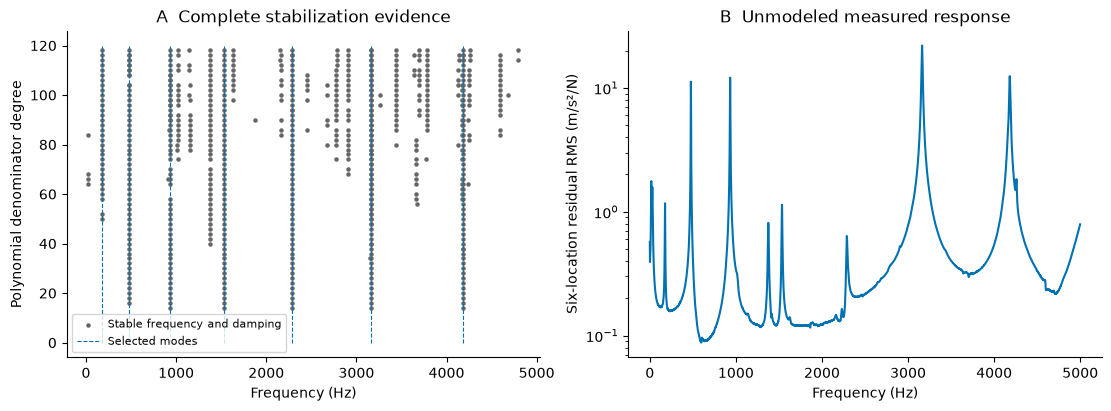

In [4]:
for figure_name,figure in figures.items():
    display(Markdown('### '+figure_name.replace('_',' ').title()))
    display(figure)
    plt.close(figure)

## Interpretation and limitations

All seven selected modes and all six spatial residue vectors are retained, along with both complex residual terms. Frequency estimates are stable across polynomial orders, while damping of the first mode changes substantially and the response residual is not monotonic in maximum order. The baseline is a reproducible selected seven-mode approximation, not an exact model of every measured spectral feature. Calibration perturbations can change the selected stable pole for high modes; the figure exposes this discontinuity. Spatial curves use roving index, not invented coordinates or mass-normalized mode shapes.

Agreement with the standard method establishes implementation fidelity. Independent mathematical tests check operators and signs, while measured residuals and sensitivity studies bound physical interpretation. No reconstruction is relabeled as ground truth.

## Sources

Peeters et al., The PolyMAX frequency-domain method: a new standard for modal parameter estimation?, Shock and Vibration 11 (2004), 395–409. https://doi.org/10.1155/2004/523692

Data and executable method source are the author-maintained experimental/operational modal-analysis package and its measured accelerance showcase; this is a modern numerical port, not the original commercial software implementation.